## Dataset Discovery and EDA Notebook

In [2]:
from pathlib import Path

data_dir = Path("/Users/sand/Downloads/OneDrive_5_11-8-2026")
files = sorted(data_dir.glob("*.mat"))

print("Files found:", len(files))
print([file.name for file in files[:5]])

Files found: 6
['p000047.mat', 'p000050.mat', 'p000056.mat', 'p000058.mat', 'p000059.mat']


In [3]:
import mat73

data = mat73.loadmat(str(files[0]))

print(data.keys())

for key, value in data.items():
    print(key, type(value), getattr(value, "shape", None))

dict_keys(['Subj_Wins'])
Subj_Wins <class 'dict'> None


In [4]:
data.keys()
type(data["Subj_Wins"])
data["Subj_Wins"].keys()

dict_keys(['ABP_F', 'ABP_Lag', 'ABP_Raw', 'ABP_SPeaks', 'ABP_Turns', 'Age', 'BMI', 'CaseID', 'ECG_F', 'ECG_RPeaks', 'ECG_Raw', 'ECG_Record', 'ECG_Record_F', 'Gender', 'Height', 'IncludeFlag', 'PPG_ABP_Corr', 'PPG_F', 'PPG_Raw', 'PPG_Record', 'PPG_Record_F', 'PPG_SPeaks', 'PPG_Turns', 'SegDBP', 'SegSBP', 'SegmentID', 'SubjectID', 'T', 'Weight', 'WinID', 'WinSeqID'])

In [5]:
windows = data["Subj_Wins"]
type(windows["ECG_F"][0][0])
# len(windows["ECG_F"])
# type(windows["ECG_F"][0])
# len(windows["SegSBP"])

len(windows["ECG_F"])     # Number of segments
len(windows["ECG_F"][0])

1

In [6]:
type(windows["ECG_F"][0][0])
type(windows["T"][0][0])
windows["ECG_F"][0][0].shape

ecg = windows["ECG_F"][0][0]
t = windows["T"][0][0]

Text(0, 0.5, 'Normalized ECG amplitude')

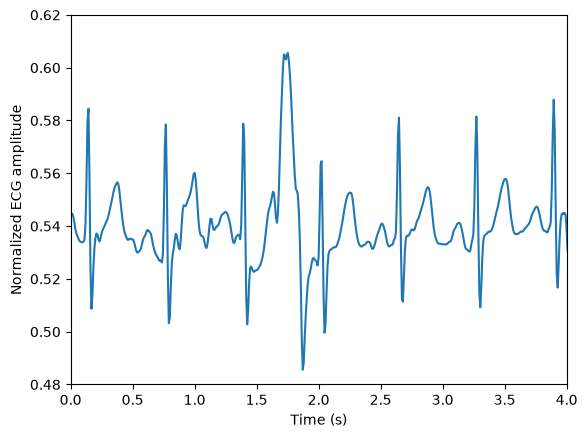

In [7]:
t[:5] # 125 Hz (deltat = 0.008 sec)

import matplotlib.pyplot as plt

plt.plot(t - t[0], ecg)
plt.xlim(0, 4)
plt.ylim(0.48, 0.62)
plt.xlabel("Time (s)")
plt.ylabel("Normalized ECG amplitude")

(0.0, 1.0)

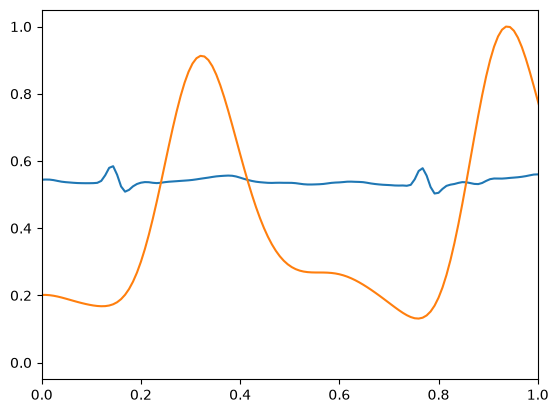

In [8]:
# fig, axes = plt.subplots(2, 1, sharex=True)

ppg = windows["PPG_F"][0][0]

ecg_raw = windows["ECG_Raw"][0][0]

plt.plot(t - t[0], ecg)
plt.xlim(0, 1)
# plt.ylim(0.48, 0.62)
plt.plot(t - t[0], ppg)
plt.xlim(0,1)
# plt.ylim(0.48, 0.62)

(0.0, 3.0)

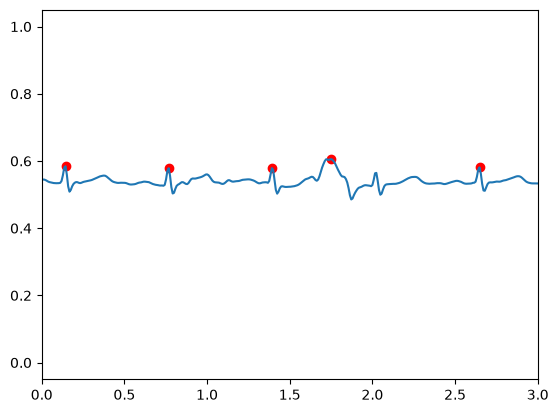

In [9]:
from scipy.signal import find_peaks

relative_time = t - t[0]
mask = relative_time < 4
min_distance = int(0.3 * 125)

peaks_ecg, properties_ecg = find_peaks(ecg, height=(0.57), distance=min_distance) #, 0.64))
# print(peaks)
# ecg[peaks]

plt.plot(relative_time, ecg)
plt.scatter(relative_time[peaks_ecg], ecg[peaks_ecg], color="red")
plt.xlim(0, 3)

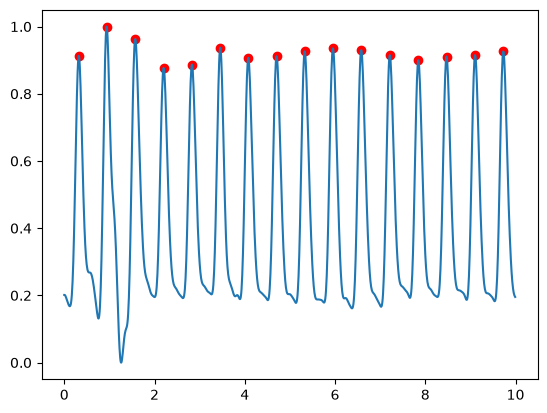

In [10]:
peaks_ppg, properties_ppg = find_peaks(ppg, height=0.7, distance=min_distance)
# print(peaks)
# ecg[peaks]

plt.plot(relative_time, ppg)
plt.scatter(relative_time[peaks_ppg], ppg[peaks_ppg], color="red")
#plt.xlim(0, 1)

(0.0, 10.0)

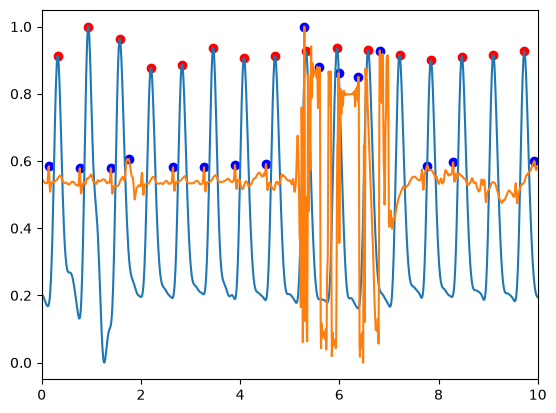

In [11]:
plt.plot(relative_time, ppg)
plt.plot(relative_time, ecg)
plt.scatter(relative_time[peaks_ppg], ppg[peaks_ppg], color="red")
plt.scatter(relative_time[peaks_ecg], ecg[peaks_ecg], color="blue")
plt.xlim(0, 10)



In [12]:
ecg[peaks_ecg]
tpeaks_ecg = relative_time[peaks_ecg]
tpeaks_ecg

array([0.144, 0.768, 1.392, 1.752, 2.648, 3.272, 3.896, 4.52 , 5.296,
       5.6  , 5.984, 6.384, 6.816, 7.776, 8.296, 9.928])

In [13]:
ppg[peaks_ppg]
tpeaks_ppg = relative_time[peaks_ppg]
tpeaks_ppg

array([0.32 , 0.936, 1.576, 2.2  , 2.832, 3.456, 4.08 , 4.704, 5.328,
       5.952, 6.584, 7.216, 7.848, 8.472, 9.104, 9.728])

In [14]:
import numpy as np

tppg_padded = np.pad(tpeaks_ppg, (0, len(tpeaks_ecg) - len(tpeaks_ppg)), 'constant', constant_values=0)

In [15]:
# PTT Calculation

tpeaks_diff = tppg_padded - tpeaks_ecg 
tpeaks_diff_norm = np.maximum(0, tpeaks_diff)
tpeaks_diff_norm

# values gathered from looking at array
tpeaks_extracted = np.array([0.176, 0.168, 0.184, 0.184, 0.184, 0.184, 0.184])
pat_median = np.median(tpeaks_extracted)

In [16]:
# HRV Calculation

hrv_ecg = np.diff(tpeaks_ecg)
hrv_ecg
hrv_ppg = np.diff(tpeaks_ppg)
hrv_ppg


array([0.616, 0.64 , 0.624, 0.632, 0.624, 0.624, 0.624, 0.624, 0.624,
       0.632, 0.632, 0.632, 0.624, 0.632, 0.624])

In [17]:
windows["SegSBP"][0]

# plt.plot(t - t[0], bp)

import pandas as pd

row = {
    "window_index": 0,
    "pat_median_s": pat_median,
    "sbp": windows["SegSBP"][0][0].item()
}

df = pd.DataFrame([row])
df

,window_index,pat_median_s,sbp
0,0,0.184,91.794847


In [18]:
rows = [row]
df = pd.DataFrame(rows)

In [19]:
rows[0]["subject_id"] = windows["SubjectID"][0][0]
df = pd.DataFrame(rows)
df

,window_index,pat_median_s,sbp,subject_id
0,0,0.184,91.794847,p000047


In [20]:
len(windows["SegSBP"])
for i, value in enumerate(windows["SegSBP"]):
    print(i, value)

0 [array(91.79484667)]
1 [array(88.81009025)]
2 [array(92.9257259)]
3 [array(92.08163047)]
4 [array(92.7470612)]
5 [array(95.89926716)]
6 [array(98.26046732)]
7 [array(95.22691722)]
8 [array(94.35670907)]


In [21]:
for i in range(len(windows["SegSBP"])):
    window_t = windows["T"][i][0]
    sbp = windows["SegSBP"][i][0].item()

    print(i, window_t[0], window_t[-1], sbp)

0 350.008 360.0 91.79484667212479
1 360.008 370.0 88.81009025428817
2 560.008 570.0 92.92572590215222
3 570.008 580.0 92.08163047113064
4 600.008 610.0 92.74706119856562
5 640.008 650.0 95.8992671581762
6 650.008 660.0 98.26046732141411
7 660.008 670.0 95.22691722249054
8 1070.008 1080.0 94.35670907465452


In [22]:
# now that i know the theory behind it, time to use ai!

import numpy as np
import pandas as pd
from scipy.signal import find_peaks

rows = []

# Experimental settings: adjust after checking the plots
ecg_height = (0.57, 0.65)
ppg_prominence = 0.2
min_peak_spacing_s = 0.3
min_delay_s = 0.08
max_delay_s = 0.4

for i in range(len(windows["ECG_F"])):

    # 1. Extract matching signals and timestamps
    ecg = np.asarray(windows["ECG_F"][i][0]).ravel()
    ppg = np.asarray(windows["PPG_F"][i][0]).ravel()
    t = np.asarray(windows["T"][i][0]).ravel()

    if not (len(ecg) == len(ppg) == len(t)):
        raise ValueError(f"Signal lengths do not match in window {i}")

    # 2. Determine sampling rate
    fs = 1 / np.median(np.diff(t))
    min_distance = max(1, int(np.ceil(min_peak_spacing_s * fs)))

    # 3. Detect candidate peaks
    ecg_peaks, _ = find_peaks(
        ecg,
        height=ecg_height,
        distance=min_distance
    )

    ppg_peaks, _ = find_peaks(
        ppg,
        prominence=ppg_prominence,
        distance=min_distance
    )

    ecg_times = t[ecg_peaks]
    ppg_times = t[ppg_peaks]

    # 4. Match peaks without reusing a PPG peak
    delays = []
    next_ppg = 0

    for ecg_time in ecg_times:

        # Skip PPG peaks that occur too early
        while (
            next_ppg < len(ppg_times)
            and ppg_times[next_ppg] < ecg_time + min_delay_s
        ):
            next_ppg += 1

        if next_ppg == len(ppg_times):
            break

        delay = ppg_times[next_ppg] - ecg_time

        if delay <= max_delay_s:
            delays.append(delay)
            next_ppg += 1

    # 5. Store one summary row for this window
    rows.append({
        "window_index": i,
        "subject_id": windows["SubjectID"][i][0],
        "start_s": t[0],
        "last_sample_s": t[-1],
        "n_ecg_peaks": len(ecg_peaks),
        "n_ppg_peaks": len(ppg_peaks),
        "n_matched_pairs": len(delays),
        "pat_median_s": np.median(delays) if delays else np.nan,
        "sbp": windows["SegSBP"][i][0].item(),
        "dbp": windows["SegDBP"][i][0].item()
    })

df = pd.DataFrame(rows)
df

,window_index,subject_id,start_s,last_sample_s,n_ecg_peaks,n_ppg_peaks,n_matched_pairs,pat_median_s,sbp,dbp
0,0,p000047,350.008,360.0,12,16,9,0.184,91.794847,61.343359
1,1,p000047,360.008,370.0,1,16,1,0.384,88.810090,60.416102
2,2,p000047,560.008,570.0,19,18,12,0.216,92.925726,59.380332
3,3,p000047,570.008,580.0,12,17,7,0.280,92.081630,59.026496
4,4,p000047,600.008,610.0,5,17,4,0.172,92.747061,59.203757
5,5,p000047,640.008,650.0,12,18,8,0.268,95.899267,61.292664
6,6,p000047,650.008,660.0,11,17,7,0.168,98.260467,62.926364
7,7,p000047,660.008,670.0,21,17,12,0.252,95.226917,60.562905
8,8,p000047,1070.008,1080.0,0,13,0,NaN,94.356709,58.020955


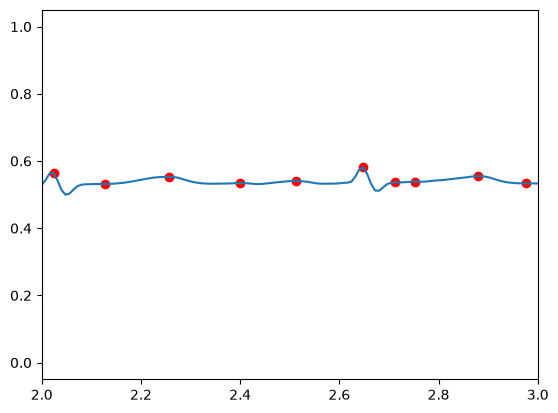

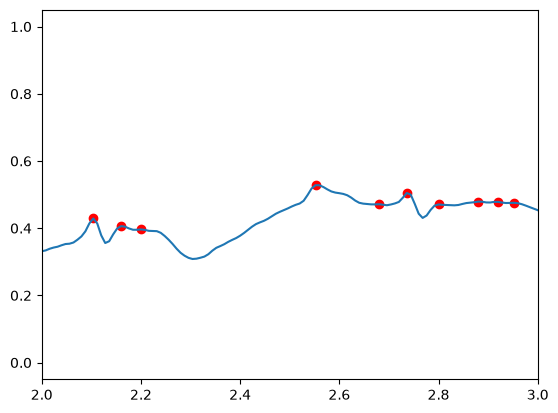

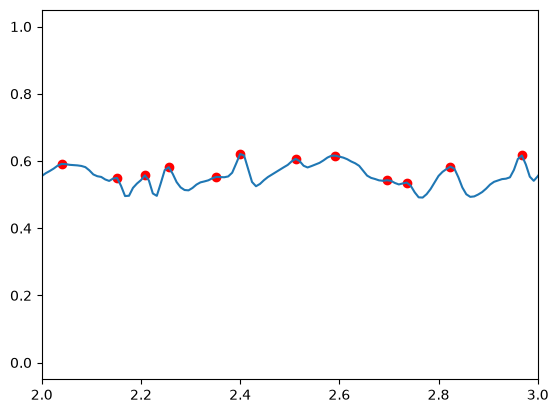

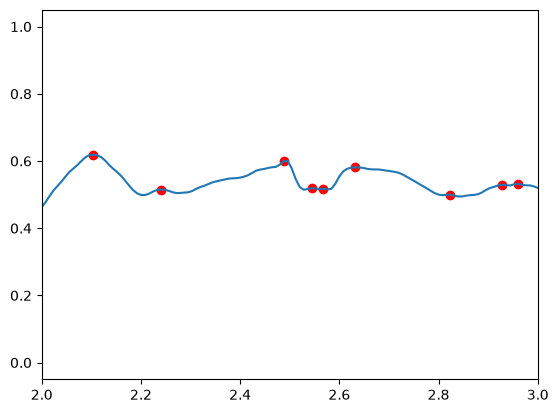

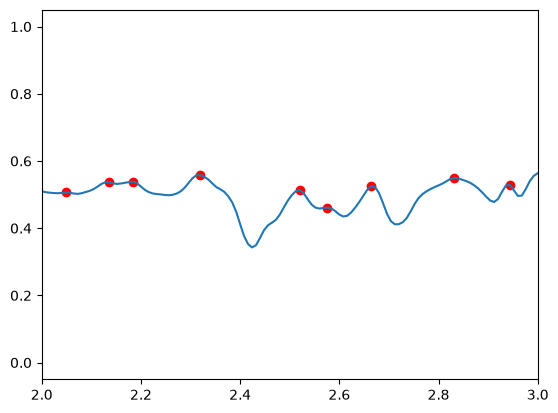

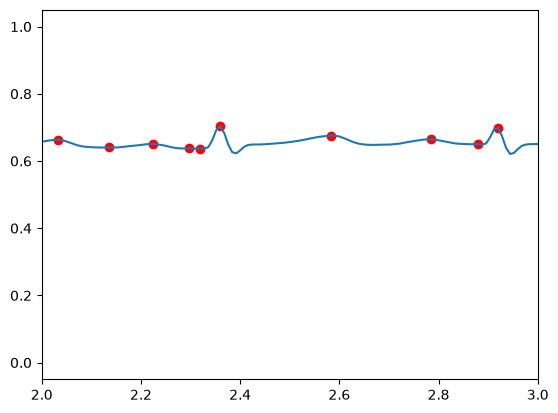

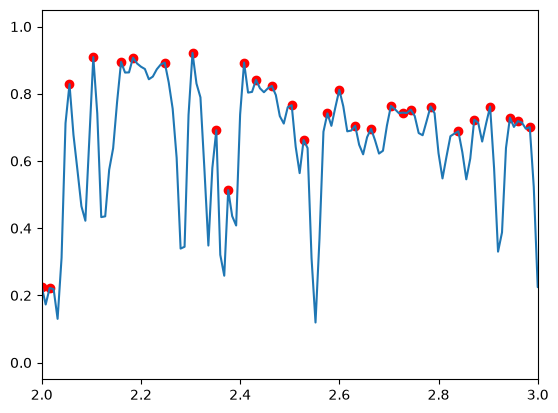

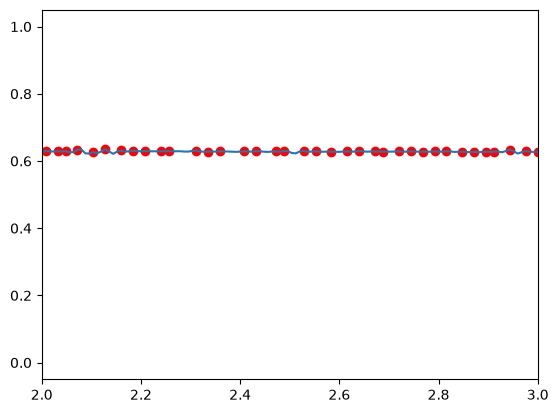

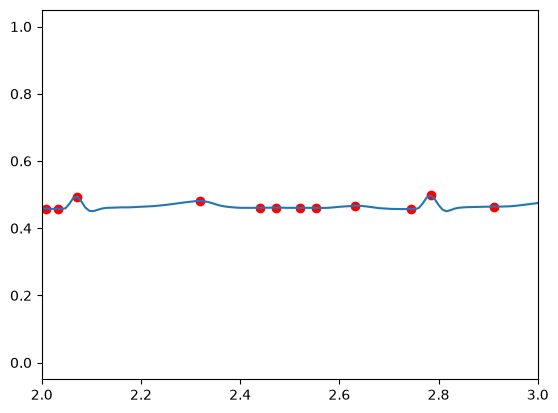

In [23]:
for i in range(9):
    ecg_i = windows["ECG_F"][i][0]

    peaks_ecg_i, properties_ecg_i = find_peaks(ecg_i)#, distance=min_distance) #, 0.64))
    
    fig, ax = plt.subplots()
    plt.plot(relative_time, ecg_i)
    plt.scatter(relative_time[peaks_ecg_i], ecg_i[peaks_ecg_i], color="red")
    plt.xlim(2,3)

In [24]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 1. Clean the data: Drop rows where pat_median_s is missing (like row 8)
# Optional: Filter out windows with very few matched pairs (e.g., less than 5)
clean_df = df.dropna(subset=["pat_median_s"])
clean_df = clean_df[clean_df["n_matched_pairs"] >= 5]

# 2. Define your Feature Matrix (X) and Target Vectors (Y)
# We'll use 'pat_median_s' as our primary physiological feature
X = clean_df[["pat_median_s"]]

y_sbp = clean_df["sbp"]
y_dbp = clean_df["dbp"]

# 3. Initialize and fit the Linear Regression model for Systolic BP
sbp_model = LinearRegression()
sbp_model.fit(X, y_sbp)

# 4. Initialize and fit the Linear Regression model for Diastolic BP
dbp_model = LinearRegression()
dbp_model.fit(X, y_dbp)

# 5. Check the learned parameters and basic performance
print("--- Systolic BP Model ---")
print(f"Intercept: {sbp_model.intercept_:.2f}")
print(f"Coefficient (Slope): {sbp_model.coef_[0]:.2f}")
print(f"R² Score: {r2_score(y_sbp, sbp_model.predict(X)):.2f}")

print("\n--- Diastolic BP Model ---")
print(f"Intercept: {dbp_model.intercept_:.2f}")
print(f"Coefficient (Slope): {dbp_model.coef_[0]:.2f}")
print(f"R² Score: {r2_score(y_dbp, dbp_model.predict(X)):.2f}")

--- Systolic BP Model ---
Intercept: 97.39
Coefficient (Slope): -13.26
R² Score: 0.06

--- Diastolic BP Model ---
Intercept: 65.35
Coefficient (Slope): -20.14
R² Score: 0.42


In [26]:
# 1-D CNN Model

import torch
import torch.nn as nn

class BP_1D_CNN(nn.Module):
    def __init__(self):
        super().__init__()
        
        self.features = nn.Sequential(
            nn.Conv1d(1, 16, kernel_size=7, padding=3),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),

            nn.Conv1d(16, 32, kernel_size=5, padding=2),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),

            nn.AdaptiveAvgPool1d(1),
            nn.Flatten(start_dim=1)
        )

        self.output = nn.Linear(32, 2)

    def forward_features(self, x):
        return self.features(x)

    def forward(self, x):
        embedding = self.forward_features(x)
        return self.output(embedding)

In [28]:
x = torch.tensor(ppg, dtype=torch.float32)
x = x.unsqueeze(0).unsqueeze(0)

print(x.shape)  # torch.Size([1, 1, 1250])

model = BP_1D_CNN()

with torch.no_grad():
    predictions = model(x)
    embedding = model.forward_features(x)

print(predictions.shape)  # torch.Size([1, 2])
print(embedding.shape)    # torch.Size([1, 32])

torch.Size([1, 1, 1250])
torch.Size([1, 2])
torch.Size([1, 32])


In [29]:
ppg_windows = []
bp_labels = []
subject_ids = []

for i in range(len(windows["PPG_F"])):
    ppg_windows.append(
        np.asarray(windows["PPG_F"][i][0]).ravel()
    )

    bp_labels.append([
        windows["SegSBP"][i][0].item(),
        windows["SegDBP"][i][0].item()
    ])

    subject_ids.append(windows["SubjectID"][i][0])

In [30]:
X = torch.tensor(
    np.stack(ppg_windows),
    dtype=torch.float32
).unsqueeze(1)

y = torch.tensor(
    bp_labels,
    dtype=torch.float32
)

print("Inputs:", X.shape)
print("Targets:", y.shape)
print("Unique subjects:", len(set(subject_ids)))

Inputs: torch.Size([9, 1, 1250])
Targets: torch.Size([9, 2])
Unique subjects: 1


In [31]:
print(torch.isfinite(X).all())
print(torch.isfinite(y).all())

tensor(True)
tensor(True)


In [32]:
# Run the CNN 

loss_fn = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

In [33]:
model.train()

for epoch in range(300):

    # Remove gradients left over from the previous iteration
    optimizer.zero_grad()

    # Predict SBP and DBP for all nine windows
    predictions = model(X)

    # Compare predictions with reference labels
    loss = loss_fn(predictions, y)

    # Calculate how each parameter affects the loss
    loss.backward()

    # Update the parameters
    optimizer.step()

    if (epoch + 1) % 25 == 0:
        print(f"Epoch {epoch + 1}: MSE = {loss.item():.2f}")

Epoch 25: MSE = 6115.17
Epoch 50: MSE = 5897.56
Epoch 75: MSE = 5310.42
Epoch 100: MSE = 4113.44
Epoch 125: MSE = 2392.38
Epoch 150: MSE = 833.63
Epoch 175: MSE = 179.86
Epoch 200: MSE = 69.81
Epoch 225: MSE = 38.90
Epoch 250: MSE = 32.37
Epoch 275: MSE = 31.34
Epoch 300: MSE = 31.16


In [34]:
model.eval()

with torch.no_grad():
    predictions = model(X)
    mae = torch.mean(torch.abs(predictions - y), dim=0)

print("Training SBP MAE:", mae[0].item(), "mmHg")
print("Training DBP MAE:", mae[1].item(), "mmHg")

print("First reference:", y[0])
print("First prediction:", predictions[0])

Training SBP MAE: 6.000088214874268 mmHg
Training DBP MAE: 3.546175956726074 mmHg
First reference: tensor([91.7948, 61.3434])
First prediction: tensor([101.8633,  65.7621])


In [35]:
mean_bp = y.mean(dim=0)

baseline_predictions = mean_bp.expand_as(y)

baseline_mae = torch.mean(
    torch.abs(baseline_predictions - y),
    dim=0
)

print("Mean-BP baseline MAE:", baseline_mae)
print("CNN predictions:\n", predictions)

Mean-BP baseline MAE: tensor([2.1057, 1.1854])
CNN predictions:
 tensor([[101.8633,  65.7621],
        [ 86.4395,  55.7796],
        [ 90.4810,  58.3976],
        [ 88.7868,  57.3007],
        [ 98.2294,  63.4119],
        [104.7831,  67.6508],
        [ 91.7382,  59.2107],
        [ 91.8897,  59.3089],
        [ 82.7601,  53.4051]])


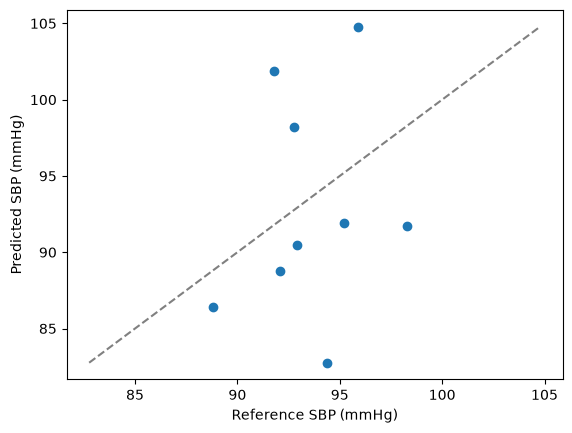

In [36]:
plt.scatter(
    y[:, 0].numpy(),
    predictions[:, 0].numpy()
)

low = min(y[:, 0].min().item(), predictions[:, 0].min().item())
high = max(y[:, 0].max().item(), predictions[:, 0].max().item())

plt.plot([low, high], [low, high], "--", color="gray")
plt.xlabel("Reference SBP (mmHg)")
plt.ylabel("Predicted SBP (mmHg)")
plt.show()

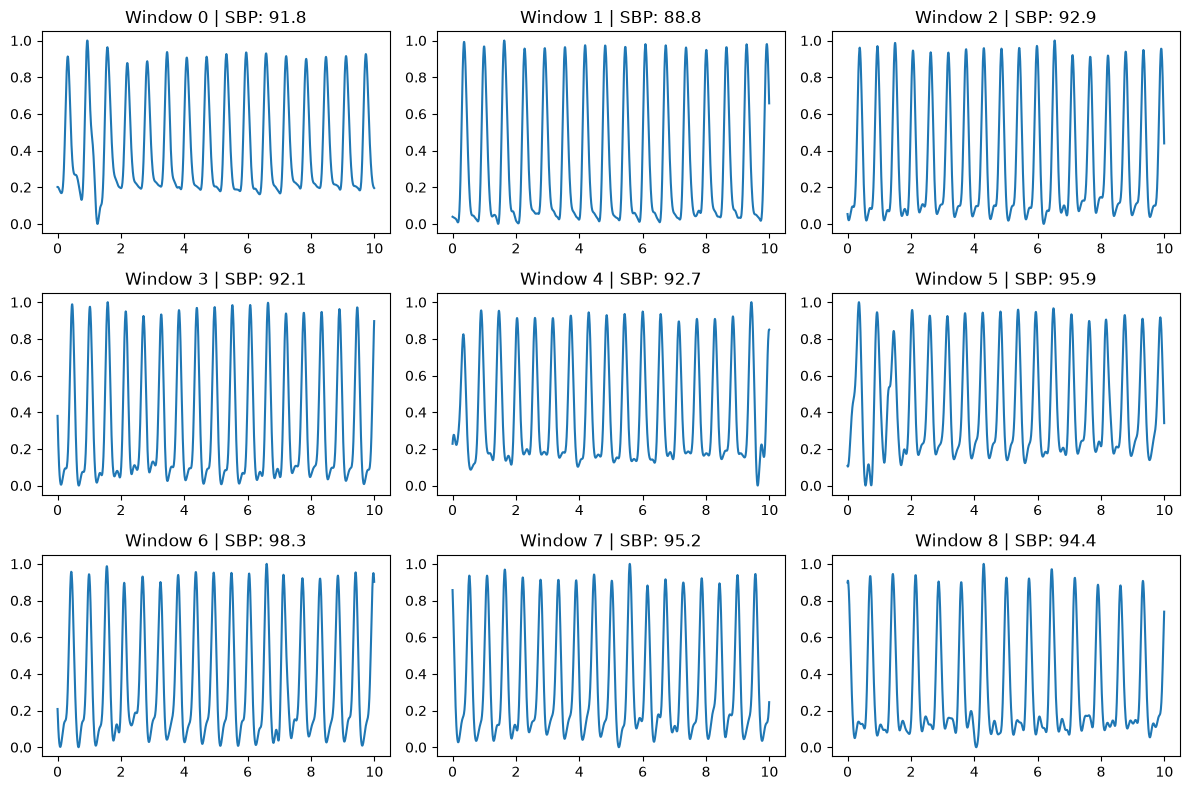

In [37]:
fig, axes = plt.subplots(3, 3, figsize=(12, 8))

for i, ax in enumerate(axes.flat):
    ax.plot(np.arange(X.shape[-1]) / 125, X[i, 0].numpy())
    ax.set_title(f"Window {i} | SBP: {y[i, 0].item():.1f}")

plt.tight_layout()